# 유전자 변이 기반 암 아형(SUBCLASS) 분류 — LightGBM + 로지스틱 회귀 (피처 확장판)

**구성**
1. **전처리**: Test의 결측치(NaN)를 `WT`(변이 없음)로 처리하고, 변이 문자열을 종류별(침묵·미스센스·절단)로 파싱합니다.
2. **피처 생성**: 변이 토큰(`TP53`, `TP53__R273H`, `TP53__TRUNC`) 희소 행렬 + 행 단위 변이 통계 + 새 피처(변이 비율, 다중 변이, 과변이 여부, 핫스팟 변이 수).
3. **LightGBM** 다중 분류. 유전자 간 조합 효과(예: IDH1 변이 + 다른 변이 동시 존재)를 트리가 잡아냅니다.
4. **그룹 5-Fold CV**: 변이 프로필이 똑같은 환자(KIPAN↔KIRC, GBMLGG↔LGG 중복)를 같은 fold에 묶어 점수 왜곡을 막습니다.
5. 로지스틱 회귀와 앙상블해서 OOF 점수가 오르면 사용합니다.
6. **판정 기준 보정값은 쓰지 않습니다.** 보정값을 뺐을 때 리더보드가 0.3162 → 0.3246으로 올랐습니다 (Train과 Test의 클래스 분포가 다르다는 근거).

**피처 스위치**

| 스위치 | 내용 | 리더보드 |
|---|---|---|
| `USE_NEW_FEATURES` | 1차 새 피처 5개 (변이 비율, 다중 변이, 과변이, 핫스팟 수) | True: 0.3355 / False: 0.3261 |
| `USE_MORE_FEATURES` | **2차 확장 피처**: 아미노산 치환 패턴, 변이 위치(코돈) 토큰, 넌센스·프레임시프트 분리, 데이터 기반 유전자 그룹 | 새로 추가 (미제출) |

2차 확장 피처의 사전 실험 (그룹 5-Fold OOF Macro F1, 로지스틱 회귀 단독): 기존 0.4206 → 코돈 토큰 0.4276 → **아미노산 치환 0.4858** → 둘 다 **0.4888**

**Data Leakage 방지 (운영계획서 5장)**
- 파싱·통계·프로필 해시는 **각 행 안에서만** 계산합니다.
- 결측치는 Test 통계가 아닌 **고정값 `WT`**로 채웁니다.
- 어휘(Vectorizer)·LabelEncoder·과변이 기준값·핫스팟 목록·모델은 **Train(학습 fold)으로만** 정하고 Test에는 적용만 합니다.
- Test로 EDA를 하지 않고, `get_dummies`를 쓰지 않습니다.

**실행 환경**: Colab 권장 (LightGBM 기본 설치). CPU로 충분합니다.

## 1. 환경 설정

In [1]:
import os, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import scipy.sparse as sp
import lightgbm as lgb

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import LabelEncoder

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
seed_everything()
print('LightGBM', lgb.__version__)

DATA_DIR = '/content/sample_data'

USE_NEW_FEATURES = True     # 1차 새 피처 (리더보드 0.3355)
USE_MORE_FEATURES = True    # 2차 확장 피처 (아미노산 치환, 코돈 토큰, 넌센스/프레임시프트, 유전자 그룹)

LightGBM 4.6.0


## 2. 데이터 불러오기

In [2]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
submission = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

GENES = [c for c in train.columns if c not in ('ID', 'SUBCLASS')]
assert [c for c in test.columns if c != 'ID'] == GENES
print('train:', train.shape, '| test:', test.shape)

le = LabelEncoder().fit(train['SUBCLASS'])     # Train 정답으로만 fit
y = le.transform(train['SUBCLASS'])
K = len(le.classes_)

train: (6201, 4386) | test: (2546, 4385)


## 2-1. 전처리: 결측치 확인 및 처리

이 데이터에서 "변이 없음"은 NaN이 아니라 **`WT`(Wild Type)** 값으로 표시됩니다.
- Train에는 NaN이 없고, Test에는 일부 칸(약 237칸, 128명)에 NaN이 있습니다.
- 처리하지 않으면 NaN이 `'nan'`이라는 글자가 되어 **"변이가 있는 것"으로 잘못 계산**됩니다.
- 결측 = 변이 없음으로 보고 **고정값 `WT`**로 채웁니다. 평균·최빈값 같은 Test 통계를 쓰지 않으므로 규정 위반이 아닙니다.

In [3]:
print('NaN 칸 수 — train:', int(train[GENES].isnull().sum().sum()), '| test:', int(test[GENES].isnull().sum().sum()))
print('빈 문자열 칸 수 — train:', int((train[GENES] == '').sum().sum()))

def fill_missing(df):
    df = df.copy()
    df[GENES] = df[GENES].fillna('WT').astype(str).replace({'': 'WT', 'nan': 'WT'})
    return df

train, test = fill_missing(train), fill_missing(test)
print('처리 후 NaN 칸 수 — test:', int(test[GENES].isnull().sum().sum()))
print(f"전체 칸 중 WT 비율 (train): {(train[GENES] == 'WT').values.mean():.2%}  → 매우 희소한 데이터")

NaN 칸 수 — train: 0 | test: 237
빈 문자열 칸 수 — train: 0
처리 후 NaN 칸 수 — test: 0
전체 칸 중 WT 비율 (train): 99.19%  → 매우 희소한 데이터


## 3. 그룹 교차검증 (중복 프로필을 같은 fold로)

In [4]:
groups = pd.util.hash_pandas_object(train[GENES], index=False).values   # 행 단위 해시
print('중복 프로필 행 수:', pd.Series(groups).duplicated(keep=False).sum())
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, y, groups))

중복 프로필 행 수: 1016


## 4. 전처리: 변이 파싱 (행 단위)

한 칸의 값은 `WT`, `V600E` 또는 `Q369* I368N`처럼 **공백으로 구분된 여러 변이**일 수 있어, 공백으로 나눠 하나씩 처리합니다. 변이는 세 종류로 나눕니다.

| 종류 | 판단 기준 | 예시 | 의미 |
|---|---|---|---|
| 침묵(silent) | 앞뒤 아미노산이 같음 | `R895R` | 단백질 변화 없음 |
| 절단(truncating) | `*`(넌센스) 또는 `fs`(프레임시프트) 포함 | `Q369*`, `K120fs` | 단백질이 끊기거나 파괴됨 |
| 미스센스(missense) | 그 외 아미노산 치환 | `V600E` | 아미노산 하나가 바뀜 |

환자마다 두 개의 토큰 문서를 만듭니다.
- **all 문서**: 변이가 있는 모든 유전자 (침묵 포함)
- **ns 문서**: 아미노산이 바뀌는 변이 유전자 + 구체적 변이(`TP53__R273H`) + 절단 변이(`TP53__TRUNC`)

In [5]:
SILENT = re.compile(r'^([A-Z])\d+\1$')            # 예: R895R (아미노산 변화 없음)
PARSE  = re.compile(r'^([A-Z*\-]+?)(\d+)(.*)$')       # 예: R132H → ('R', '132', 'H'), K120fs → ('K', '120', 'fs')

def build_docs(df, genes=GENES):
    docs_all, docs_ns, docs_codon, docs_trans, stats = [], [], [], [], []
    for row in df[genes].itertuples(index=False):
        tok_all, tok_ns, tok_codon, tok_trans = [], [], [], []
        n_gene = n_total = n_silent = n_trunc = n_missense = 0
        n_nonsense = n_frameshift = n_multi_gene = max_mut_in_gene = 0
        for gene, value in zip(genes, row):
            if value == 'WT':
                continue
            n_gene += 1
            muts = str(value).split()
            n_multi_gene += len(muts) > 1
            max_mut_in_gene = max(max_mut_in_gene, len(muts))
            for mut in muts:
                n_total += 1
                tok_all.append(gene)
                if SILENT.match(mut):
                    n_silent += 1
                    continue
                tok_ns += [gene, f'{gene}__{mut}']
                p = PARSE.match(mut)
                if p:
                    tok_codon.append(f'{gene}__{p.group(1)}{p.group(2)}')     # 변이 위치(코돈): IDH1__R132
                if 'fs' in mut or mut.endswith('*'):
                    n_trunc += 1
                    tok_ns.append(f'{gene}__TRUNC')
                    if 'fs' in mut: n_frameshift += 1
                    else:           n_nonsense += 1
                else:
                    n_missense += 1
                    if p and len(p.group(1)) == 1 and len(p.group(3)) == 1:
                        tok_trans.append(f'{p.group(1)}>{p.group(3)}')       # 아미노산 치환: R>H
        docs_all.append(' '.join(tok_all))
        docs_ns.append(' '.join(tok_ns))
        docs_codon.append(' '.join(dict.fromkeys(tok_codon)))
        docs_trans.append(' '.join(tok_trans))
        tot = max(n_total, 1)
        row_stats = [n_gene, n_total, n_silent, n_trunc, n_missense,          # 앞 5개: 로지스틱 회귀도 사용
                     n_silent / tot, n_trunc / tot]
        if USE_NEW_FEATURES:
            row_stats += [n_missense / tot, n_multi_gene, max_mut_in_gene]
        if USE_MORE_FEATURES:
            row_stats += [n_nonsense, n_frameshift, n_nonsense / tot, n_frameshift / tot]
        stats.append(row_stats)
    return docs_all, docs_ns, docs_codon, docs_trans, np.array(stats, dtype=np.float32)

t0 = time.time()
tr_all, tr_ns, tr_codon, tr_trans, tr_stat = build_docs(train)
te_all, te_ns, te_codon, te_trans, te_stat = build_docs(test)
pick = lambda lst, idx: [lst[i] for i in idx]
STAT_NAMES = ['n_gene', 'n_total', 'n_silent', 'n_trunc', 'n_missense', 'silent_ratio', 'trunc_ratio']
if USE_NEW_FEATURES:
    STAT_NAMES += ['missense_ratio', 'n_multi_gene', 'max_mut_in_gene']
if USE_MORE_FEATURES:
    STAT_NAMES += ['n_nonsense', 'n_frameshift', 'nonsense_ratio', 'frameshift_ratio']
print(f'파싱 완료 ({time.time()-t0:.0f}s) | 행 단위 통계 피처 {len(STAT_NAMES)}개')
print('예시 코돈 토큰:', tr_codon[1][:100])
print('예시 치환 토큰:', tr_trans[1][:60])

파싱 완료 (13s) | 행 단위 통계 피처 14개
예시 코돈 토큰: ABCC8__T1115 ATRX__L1854 DTX1__R36 FN3K__R69 GPR182__A372 HELZ2__A1690 ITGA3__G692 KLF5__C375 PLG__P
예시 치환 토큰: T>M R>H R>Q A>T A>V P>Q M>I K>M R>H


## 4-1. 피처 생성

| 피처 | 설명 | 계산 기준 |
|---|---|---|
| `n_gene`, `n_total` | 변이 유전자 수 / 총 변이 수 (변이 부담) | 행 단위 |
| `n_silent`, `n_trunc`, `n_missense` | 변이 종류별 개수 | 행 단위 |
| `silent_ratio`, `trunc_ratio` | 침묵·절단 변이 비율 | 행 단위 |
| 🆕 `missense_ratio` | 미스센스 변이 비율 (암종마다 변이 기전이 달라 비율이 다름) | 행 단위 |
| 🆕 `n_multi_gene` | 한 유전자에 변이가 2개 이상인 유전자 수 | 행 단위 |
| 🆕 `max_mut_in_gene` | 한 유전자 안의 최대 변이 수 | 행 단위 |
| 🆕 `hypermutated` | 총 변이 수가 **학습 데이터 상위 10%** 기준을 넘는지 (과변이 암: MSI 대장암, 흑색종 등) | 기준값은 **학습 fold로** |
| 🆕 `n_hotspot` | 학습 데이터에서 **10명 이상**에게 나온 구체적 변이(핫스팟)를 몇 개 가졌는지 | 핫스팟 목록은 **학습 fold로** |

- 🆕 표시는 이번에 새로 추가한 피처이며, `USE_NEW_FEATURES = False`면 모두 빠집니다.
- `hypermutated`, `n_hotspot`은 기준을 데이터에서 정해야 하므로 5장의 `TreeFeaturizer.fit()`에서 **학습 fold로만** 정합니다.

### 2차 확장 피처 (`USE_MORE_FEATURES = True`)

| 피처 | 설명 | 계산 기준 |
|---|---|---|
| 🆕 **아미노산 치환 패턴** | 미스센스 변이를 `R>H`, `E>K`처럼 "원래 아미노산>바뀐 아미노산"으로 요약. 흡연·자외선·DNA 복구 결함 등 **암종마다 다른 돌연변이 원인**이 특정 치환을 많이 만듦 | 트리: 학습 fold에서 가장 흔한 치환 `N_TRANS`개의 비율(÷ 미스센스 수) / 로지스틱 회귀: TF-IDF |
| 🆕 **변이 위치(코돈) 토큰** | `IDH1__R132`처럼 바뀐 아미노산을 빼고 위치만 남긴 토큰. R132H와 R132C처럼 **같은 자리의 다른 변이**를 하나로 묶어, 드문 변이도 핫스팟 자리면 신호로 활용 | 학습 fold 어휘 (트리 `MIN_DF`회, 로지스틱 2회 이상) |
| 🆕 `n_nonsense`, `n_frameshift` (+ 비율) | 절단 변이를 넌센스(`*`)와 프레임시프트(`fs`)로 분리. 프레임시프트는 DNA 복구 결함(MSI) 암에서 많음 | 행 단위 |
| 🆕 `n_trunc_prone` | **학습 데이터에서 절단 변이가 주로 생기는 유전자**(절단 환자 15명 이상 & 변이 환자 중 절단 비율 50% 이상)에 절단 변이가 몇 개 있는지 — 종양 억제 유전자의 기능 상실 신호를 데이터로 찾음 | 유전자 목록은 **학습 fold로** |
| 🆕 `n_recurrent_codon` | 학습 데이터에서 **10명 이상에게 변이가 생긴 위치(코돈)**를 몇 개 가졌는지 — 정확히 같은 변이가 아니어도 핫스팟 자리면 셈 | 위치 목록은 **학습 fold로** |

> 사전 실험(통계 피처만 쓴 간이 부스팅 모델, 그룹 5-Fold): 기존 통계 0.129 → +넌센스/프레임시프트 0.152 → +치환 비율 0.252 → +유전자 그룹 0.212 → **모두 0.301**


In [6]:
# 새 피처 미리보기 (Train만 사용, 행 단위 값)
print(pd.DataFrame(tr_stat, columns=STAT_NAMES).describe().T[['mean', '50%', 'max']].round(3).to_string())

                    mean     50%     max
n_gene            35.300  14.000  2393.0
n_total           41.149  14.000  9972.0
n_silent          10.786   3.000  3616.0
n_trunc            3.764   1.000   342.0
n_missense        26.599   9.000  6014.0
silent_ratio       0.224   0.227     1.0
trunc_ratio        0.115   0.088     1.0
missense_ratio     0.645   0.660     1.0
n_multi_gene       3.552   0.000  2021.0
max_mut_in_gene    1.535   1.000    64.0
n_nonsense         2.165   1.000   335.0
n_frameshift       1.598   1.000   139.0
nonsense_ratio     0.051   0.026     1.0
frameshift_ratio   0.064   0.015     1.0


## 5. 트리용 특징

트리 모델은 스케일에 영향을 받지 않으므로 TF-IDF 대신 **이진 표시(0/1)**를 씁니다.
학습 fold에서 너무 드문 토큰(`MIN_DF`회 미만)은 빼서 특징 수와 학습 시간을 줄입니다.
`USE_NEW_FEATURES = True`면 `hypermutated`, `n_hotspot` 피처의 기준값(과변이 기준, 핫스팟 목록)도 여기서 **학습 데이터로만** 정합니다.

In [9]:
MIN_DF = 3
TOKEN_KW = dict(token_pattern=r'\S+', lowercase=False, binary=True, dtype=np.float32)

HOTSPOT_MIN = 10     # 학습 데이터에서 이 인원 이상에게 나온 구체적 변이를 핫스팟으로 간주

N_TRANS = 20                          # 트리용: 학습 fold에서 가장 흔한 아미노산 치환 개수
TRUNC_MIN, TRUNC_SHARE = 15, 0.5      # 절단 경향 유전자 기준
CODON_MIN = 10                        # 반복 변이 위치(코돈) 기준

class TreeFeaturizer:
    def fit(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        self.v_all = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_all)
        self.v_ns  = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_ns)
        names = (list(self.v_all.get_feature_names_out()) +
                 [f'ns:{t}' for t in self.v_ns.get_feature_names_out()] + STAT_NAMES)
        if USE_NEW_FEATURES:                                   # 기준값은 학습 데이터로만
            self.hyper_thr = np.quantile(stat[:, 1], 0.90)
            tok = self.v_ns.transform(docs_ns)
            vocab = self.v_ns.get_feature_names_out().astype(str)
            is_mut = np.char.find(vocab, '__') >= 0
            is_trunc = np.char.endswith(vocab, '__TRUNC')
            self.hot_cols = np.where((np.asarray(tok.sum(0)).ravel() >= HOTSPOT_MIN) & is_mut & ~is_trunc)[0]
            names += ['hypermutated', 'n_hotspot']
        if USE_MORE_FEATURES:
            # (a) 변이 위치(코돈) 토큰 어휘
            self.v_codon = CountVectorizer(min_df=MIN_DF, **TOKEN_KW).fit(docs_codon)
            names += [f'codon:{t}' for t in self.v_codon.get_feature_names_out()]
            # (b) 가장 흔한 아미노산 치환 N_TRANS개
            cv = CountVectorizer(token_pattern=r'\S+', lowercase=False).fit(docs_trans)
            cnt = np.asarray(cv.transform(docs_trans).sum(0)).ravel()
            self.v_trans, self.trans_cols = cv, np.argsort(-cnt)[:N_TRANS]
            names += [f'trans:{t}' for t in cv.get_feature_names_out()[self.trans_cols]]
            # (c) 절단 경향 유전자: 학습 데이터에서 절단 환자가 많고, 변이 중 절단 비율이 높은 유전자
            trunc_cnt, ns_cnt = Counter(), Counter()
            for d in docs_ns:
                for t in set(d.split()):
                    if t.endswith('__TRUNC'): trunc_cnt[t[:-7]] += 1
                    elif '__' not in t:      ns_cnt[t] += 1
            self.trunc_genes = {g for g, c in trunc_cnt.items() if c >= TRUNC_MIN and c / max(ns_cnt[g], 1) >= TRUNC_SHARE}
            # (d) 반복 변이 위치: 학습 데이터에서 CODON_MIN명 이상에게 변이가 생긴 코돈
            codon_cnt = np.asarray(self.v_codon.transform(docs_codon).sum(0)).ravel()
            self.rec_cols = np.where(codon_cnt >= CODON_MIN)[0]
            names += ['n_trunc_prone', 'n_recurrent_codon']
        self.feature_names = names
        return self
    def transform(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        tok_ns = self.v_ns.transform(docs_ns)
        blocks = [self.v_all.transform(docs_all), tok_ns, sp.csr_matrix(stat)]
        if USE_NEW_FEATURES:
            blocks.append(sp.csr_matrix(np.column_stack([
                (stat[:, 1] > self.hyper_thr).astype(np.float32),
                np.asarray(tok_ns[:, self.hot_cols].sum(1)).ravel()])))
        if USE_MORE_FEATURES:
            tok_codon = self.v_codon.transform(docs_codon)
            trans = self.v_trans.transform(docs_trans)[:, self.trans_cols].toarray()
            trans_ratio = trans / np.maximum(stat[:, 4:5], 1)                     # ÷ 미스센스 수
            n_tp = [sum(1 for t in d.split() if t.endswith('__TRUNC') and t[:-7] in self.trunc_genes) for d in docs_ns]
            n_rc = np.asarray(tok_codon[:, self.rec_cols].sum(1)).ravel()
            blocks += [tok_codon, sp.csr_matrix(trans_ratio), sp.csr_matrix(np.column_stack([n_tp, n_rc]).astype(np.float32))]
        return sp.hstack(blocks).tocsr().astype(np.float32)

LGB_PARAMS = dict(
    objective="multiclass",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=5,
    colsample_bytree=0.3,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
    device="gpu",
)
EARLY_STOP = 100

## 6. 그룹 5-Fold 학습 (LightGBM)

검증 fold의 `multi_logloss`로 조기 종료합니다. 각 fold의 최적 반복 수를 기록해 두었다가 최종 학습에 씁니다.

In [10]:
oof_lgb = np.zeros((len(y), K))
best_iters = []

for fold, (tr_idx, va_idx) in enumerate(folds, 1):
    t0 = time.time()
    feat = TreeFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
    X_tr = feat.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
    X_va = feat.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx], pick(tr_codon, va_idx), pick(tr_trans, va_idx))

    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y[tr_idx], eval_set=[(X_va, y[va_idx])], eval_metric='multi_logloss',
              callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False), lgb.log_evaluation(0)])
    oof_lgb[va_idx] = model.predict_proba(X_va)
    best_iters.append(model.best_iteration_)
    f1 = f1_score(y[va_idx], oof_lgb[va_idx].argmax(1), average='macro')
    print(f'Fold {fold}: Macro F1 = {f1:.4f} | best_iter = {model.best_iteration_} | 특징 {X_tr.shape[1]} ({time.time()-t0:.0f}s)')

macro = lambda P: f1_score(y, P.argmax(1), average='macro')
print(f'\nLightGBM OOF Macro F1 = {macro(oof_lgb):.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: Macro F1 = 0.5017 | best_iter = 148 | 특징 13468 (170s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2: Macro F1 = 0.4747 | best_iter = 179 | 특징 12956 (169s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3: Macro F1 = 0.4514 | best_iter = 135 | 특징 13617 (147s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 4: Macro F1 = 0.4673 | best_iter = 172 | 특징 13687 (170s)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 5: Macro F1 = 0.4771 | best_iter = 182 | 특징 13251 (175s)

LightGBM OOF Macro F1 = 0.4741


## 7. 특징 중요도 (마지막 fold 모델 기준)

In [11]:
names = feat.feature_names
imp = pd.Series(model.booster_.feature_importance('gain'), index=names).sort_values(ascending=False)
print(imp.head(25).round(1).to_string())
new_feats = [n for n in ['missense_ratio', 'n_multi_gene', 'max_mut_in_gene', 'hypermutated', 'n_hotspot',
                          'n_nonsense', 'n_frameshift', 'nonsense_ratio', 'frameshift_ratio', 'n_trunc_prone', 'n_recurrent_codon'] if n in imp.index]
if new_feats:
    rank = imp.rank(ascending=False).astype(int)
    print('\n새 피처의 중요도 순위:', {n: f'{rank[n]}위 / {len(imp)}' for n in new_feats})
if USE_MORE_FEATURES:
    for prefix, label in [('trans:', '아미노산 치환'), ('codon:', '변이 위치(코돈)')]:
        sub = imp[imp.index.str.startswith(prefix)]
        print(f'\n{label} 피처 {len(sub)}개 — 중요도 합 비중 {sub.sum() / imp.sum():.1%}, 상위 5개:')
        print(sub.head(5).round(1).to_string())

n_total              13585.6
n_gene               11914.1
n_missense            9571.9
n_silent              6645.1
trans:R>H             5663.3
missense_ratio        5290.0
silent_ratio          5030.3
trans:E>K             4670.9
frameshift_ratio      4337.4
trans:E>Q             4015.4
trunc_ratio           3588.0
n_recurrent_codon     3400.1
TP53                  3304.5
ns:TP53               3073.5
trans:R>C             2844.7
trans:R>Q             2806.7
trans:P>S             2731.8
trans:P>L             2647.2
trans:A>V             2640.7
trans:A>T             2633.9
n_hotspot             2568.3
nonsense_ratio        2546.2
trans:R>W             2540.5
trans:D>N             2486.7
max_mut_in_gene       2448.1

새 피처의 중요도 순위: {'missense_ratio': '6위 / 13251', 'n_multi_gene': '36위 / 13251', 'max_mut_in_gene': '25위 / 13251', 'hypermutated': '172위 / 13251', 'n_hotspot': '21위 / 13251', 'n_nonsense': '41위 / 13251', 'n_frameshift': '32위 / 13251', 'nonsense_ratio': '22위 / 13251', 'frameshi

## 8. 로지스틱 회귀와 앙상블

LightGBM과 성격이 다른 선형 모델을 섞으면 보통 점수가 오릅니다.
OOF 점수가 오를 때만 사용합니다 (`LR 가중치 = 0`이면 LightGBM 단독).

In [12]:
USE_LR_BLEND = True
TFIDF_KW = dict(token_pattern=r'\S+', lowercase=False, sublinear_tf=True)

TRANS_WEIGHT = 0.5     # 아미노산 치환 블록 가중치

class LinearFeaturizer:
    def fit(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        self.v_all = TfidfVectorizer(binary=True, **TFIDF_KW).fit(docs_all)
        self.v_ns  = TfidfVectorizer(min_df=2, **TFIDF_KW).fit(docs_ns)
        self.stat_max = np.log1p(stat[:, :5]).max(axis=0)
        if USE_MORE_FEATURES:
            self.v_codon = TfidfVectorizer(min_df=2, **TFIDF_KW).fit(docs_codon)
            self.v_trans = TfidfVectorizer(**TFIDF_KW).fit(docs_trans)
        return self
    def transform(self, docs_all, docs_ns, stat, docs_codon=None, docs_trans=None):
        s = np.minimum(np.log1p(stat[:, :5]), self.stat_max) * 0.3
        blocks = [self.v_all.transform(docs_all), self.v_ns.transform(docs_ns), sp.csr_matrix(s)]
        if USE_MORE_FEATURES:
            blocks += [self.v_codon.transform(docs_codon), self.v_trans.transform(docs_trans) * TRANS_WEIGHT]
        return sp.hstack(blocks).tocsr()

make_lr = lambda: LogisticRegression(C=2, class_weight='balanced', max_iter=3000)

LR_W = 0.0
if USE_LR_BLEND:
    oof_lr = np.zeros((len(y), K))
    for tr_idx, va_idx in folds:
        lf = LinearFeaturizer().fit(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx))
        oof_lr[va_idx] = make_lr().fit(lf.transform(pick(tr_all, tr_idx), pick(tr_ns, tr_idx), tr_stat[tr_idx], pick(tr_codon, tr_idx), pick(tr_trans, tr_idx)), y[tr_idx]) \
                                  .predict_proba(lf.transform(pick(tr_all, va_idx), pick(tr_ns, va_idx), tr_stat[va_idx], pick(tr_codon, va_idx), pick(tr_trans, va_idx)))
    print(f'LR 단독 OOF Macro F1 = {macro(oof_lr):.4f}')
    scores = {w: macro((1 - w) * oof_lgb + w * oof_lr) for w in np.round(np.arange(0, 1.01, 0.1), 1)}
    for w, s in scores.items():
        print(f'  LR 가중치 {w:.1f}: {s:.4f}')
    LR_W = max(scores, key=scores.get)

P_oof = (1 - LR_W) * oof_lgb + (LR_W * oof_lr if LR_W > 0 else 0)
print(f'\n선택된 LR 가중치 = {LR_W} | OOF Macro F1 = {macro(P_oof):.4f}')

LR 단독 OOF Macro F1 = 0.4868
  LR 가중치 0.0: 0.4741
  LR 가중치 0.1: 0.4759
  LR 가중치 0.2: 0.4799
  LR 가중치 0.3: 0.4859
  LR 가중치 0.4: 0.4924
  LR 가중치 0.5: 0.4987
  LR 가중치 0.6: 0.5038
  LR 가중치 0.7: 0.5038
  LR 가중치 0.8: 0.5038
  LR 가중치 0.9: 0.5013
  LR 가중치 1.0: 0.4868

선택된 LR 가중치 = 0.8 | OOF Macro F1 = 0.5038


## 9. 모델 성능 비교


In [13]:
!pip install -q koreanize-matplotlib

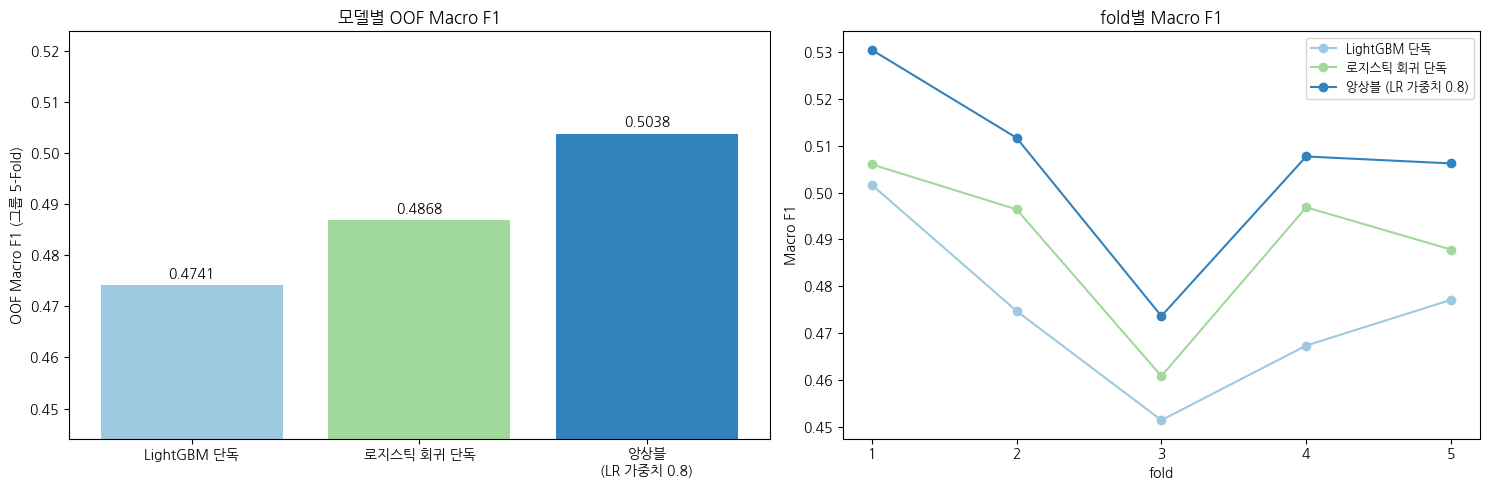

                  OOF Macro F1  fold 평균  fold 표준편차
LightGBM 단독             0.4741   0.4745     0.0163
로지스틱 회귀 단독              0.4868   0.4896     0.0155
앙상블 (LR 가중치 0.8)        0.5038   0.5060     0.0184


In [14]:
# ===== 모델 성능 비교 그래프 (9장 다음에 추가) =====
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib            # 한글 폰트 (없으면 위 pip 셀 먼저 실행)
except ImportError:
    pass
plt.rcParams['axes.unicode_minus'] = False

def f1_of(P_or_pred, idx=None):
    pred = P_or_pred if P_or_pred.ndim == 1 else P_or_pred.argmax(1)
    if idx is None:
        return f1_score(y, pred, average='macro')
    return f1_score(y[idx], pred[idx], average='macro')

# 비교할 결과 모으기 (노트북에서 이미 계산된 OOF만 사용, 재학습 없음)
results = {'LightGBM 단독': oof_lgb}
if USE_LR_BLEND:
    results['로지스틱 회귀 단독'] = oof_lr
    results[f'앙상블\n(LR 가중치 {LR_W})'] = P_oof

names = list(results)
overall = [f1_of(results[n]) for n in names]
per_fold = {n: [f1_of(results[n], va) for _, va in folds] for n in names}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.1, 1]})

# (1) 전체 OOF Macro F1 막대그래프
colors = ['#9ecae1', '#a1d99b', '#3182bd', '#08519c'][:len(names)]
bars = axes[0].bar(names, overall, color=colors)
axes[0].bar_label(bars, fmt='%.4f', padding=3)
axes[0].set_ylim(min(overall) - 0.03, max(overall) + 0.02)
axes[0].set_ylabel('OOF Macro F1 (그룹 5-Fold)')
axes[0].set_title('모델별 OOF Macro F1')

# (2) fold별 점수 (점수가 얼마나 흔들리는지)
x = np.arange(1, len(folds) + 1)
for n, c in zip(names, colors):
    axes[1].plot(x, per_fold[n], marker='o', color=c, label=n.replace('\n', ' '))
axes[1].set_xticks(x); axes[1].set_xlabel('fold'); axes[1].set_ylabel('Macro F1')
axes[1].set_title('fold별 Macro F1')
axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

summary = pd.DataFrame({'OOF Macro F1': overall,
                        'fold 평균': [np.mean(per_fold[n]) for n in names],
                        'fold 표준편차': [np.std(per_fold[n]) for n in names]},
                       index=[n.replace('\n', ' ') for n in names]).round(4)
print(summary.to_string())

## 10. 전체 Train으로 재학습 → Test 예측

In [15]:
N_FINAL = int(np.mean(best_iters) * 1.1)     # 데이터가 1/0.8배 많아지므로 반복 수를 조금 늘림
print('최종 반복 수:', N_FINAL)

feat = TreeFeaturizer().fit(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)        # Train으로만 fit
X_train = feat.transform(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)
X_test  = feat.transform(te_all, te_ns, te_stat, te_codon, te_trans)           # Test는 transform만
final_lgb = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': N_FINAL}).fit(X_train, y)
P_test = (1 - LR_W) * final_lgb.predict_proba(X_test)

if LR_W > 0:
    lf = LinearFeaturizer().fit(tr_all, tr_ns, tr_stat, tr_codon, tr_trans)
    P_test += LR_W * make_lr().fit(lf.transform(tr_all, tr_ns, tr_stat, tr_codon, tr_trans), y).predict_proba(lf.transform(te_all, te_ns, te_stat, te_codon, te_trans))

test_pred = le.inverse_transform(P_test.argmax(1))

최종 반복 수: 179


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 11. 제출 파일 저장

In [16]:
assert (submission['ID'].values == test['ID'].values).all()
submission['SUBCLASS'] = test_pred
out_name = 'submission_lightgbm_fe2.csv' if USE_MORE_FEATURES else ('submission_lightgbm_nobias_fe.csv' if USE_NEW_FEATURES else 'submission_lightgbm_nanfix_only.csv')
submission.to_csv(out_name, index=False, encoding='UTF-8-sig')
print('저장:', out_name)
print(submission['SUBCLASS'].value_counts().head(10).to_string())

저장: submission_lightgbm_fe2.csv
SUBCLASS
COAD      501
STES      391
KIPAN     188
BRCA      187
OV        106
GBMLGG    103
PRAD      100
LUSC       95
UCEC       77
KIRC       77


## 튜닝 팁 (반드시 그룹 CV 점수로만 판단)
- `num_leaves` (7~31), `colsample_bytree` (0.1~0.5), `min_child_samples` (3~20), `MIN_DF` (2~10)
- `learning_rate`를 0.02로 낮추면 대개 조금 좋아지지만 학습 시간이 늘어납니다.
- 조기 종료에 검증 fold를 쓰므로 OOF 점수가 아주 약간 낙관적일 수 있습니다.
- KIPAN/KIRC, GBMLGG/LGG는 같은 환자가 두 라벨로 존재해서 줄일 수 없는 오차가 있습니다.